# 11 — נתוני רמת גן החדשים: סקירה ראשונית לקראת הפגישה עם אורן

שני קבצים חדשים נחתו תחת `ramat_gan/`:

- `wetag-gis-2026-11-15.geojson` — קובץ מיקומים/מטא-דאטה של החיישנים (מערכת WeTag).
- `חיישן טמפרטורה ולחות - sensor data (raw) - 2026-08-17 to 2026-11-15.csv` —
  קריאות טמפרטורה גולמיות.

המטרה כאן היא רק להכיר את הדאטה כמו שהוא — היקף, איכות, אי-התאמות — ולא
לבנות פייפליין. השאלות הפתוחות שעלו מתוך הבדיקה מרוכזות בסוף.


In [1]:
import json

import contextily as ctx
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from shapely import MultiPoint, voronoi_polygons
from shapely.geometry import Point

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

RAW_DIR = "../ramat_gan"
GIS_PATH = f"{RAW_DIR}/wetag-gis-2026-11-15.geojson"
TEMP_PATH = f"{RAW_DIR}/חיישן טמפרטורה ולחות - sensor data (raw) - 2026-08-17 to 2026-11-15.csv"
BOUNDARY_PATH = "../data/raw/geo/ramat_gan/boundary.geojson"


## 1. קובץ המיקומים (GIS) — מי החיישנים ואיפה הם

In [2]:
sensors_gdf = gpd.read_file(GIS_PATH)
sensors_gdf["serial"] = sensors_gdf["מספר סידורי"].astype(int)
sensors_gdf["lon"] = sensors_gdf.geometry.x
sensors_gdf["lat"] = sensors_gdf.geometry.y

print(f"{len(sensors_gdf)} sensors in the GIS file")
print("sensor types:", sensors_gdf["סוג חיישן"].unique())
print("mount types:", sensors_gdf["מקום התקנה"].value_counts(dropna=False).to_dict())

sensors_gdf[["serial", "מזהה חיישן", "מספר עמוד", "מקום התקנה", "הערות", "lat", "lon"]].sort_values("serial")


28 sensors in the GIS file
sensor types: <ArrowStringArray>
['טמפרטורה ולחות', nan]
Length: 2, dtype: str
mount types: {'עמוד תאורה': 24, 'עמוד חשמל': 2, nan: 2}


,serial,מזהה חיישן,מספר עמוד,מקום התקנה,הערות,lat,lon
6,1,8072,82162,עמוד תאורה,עמוד ללא עצים לידו,32.097438,34.822581
7,2,7223,900222,עמוד תאורה,NaN,32.095050,34.811207
5,3,17439,810967,עמוד תאורה,עמוד על הצומת עם דגלים ותמרור,32.092571,34.819589
9,4,7694,NaN,NaN,NaN,32.085599,34.801519
8,5,8536,NaN,NaN,NaN,32.085403,34.801404
10,6,6465,811129,עמוד תאורה,NaN,32.082347,34.806171
11,7,17371,81113,עמוד תאורה,NaN,32.082118,34.806712
4,8,6481,2058,עמוד חשמל,NaN,32.075145,34.826095
15,9,4828,61,עמוד תאורה,עמוד עקום בין עצים,32.069823,34.837723
16,10,7967,NaN,עמוד תאורה,עמוד בתוך הפארק,32.069830,34.836490


חלק מהרשומות נושאות הערות שטח חופשיות (`הערות`) — כנראה תועדו ע"י הטכנאי
שהתקין את החיישן, ומרמזות על מיקרו-אקלים ספציפי לעמוד (צל, דשא, חניה, קרבה
למתקן מים וכו').

In [3]:
notes = sensors_gdf.loc[sensors_gdf["הערות"].notna(), ["serial", "הערות"]]
notes


,serial,הערות
2,12,שביל ליד בתים
3,11,"עמוד תאורה עגול, עם סולם, יש דשא מסביב"
5,3,עמוד על הצומת עם דגלים ותמרור
6,1,עמוד ללא עצים לידו
14,25,עמוד תאורה בתוך עצים בחניה
15,9,עמוד עקום בין עצים
16,10,עמוד בתוך הפארק
19,20,"ליד ספסל בפארק, אזור נעים מאוד"
20,21,"ליד ברזיה ומתקני ילדים, חם"
22,23,קרוב לבית


## 2. מפת החיישנים — אורתופוטו + פערי כיסוי מרחביים

מפה שמאלית: החיישנים על גבי תצלום אוויר אמיתי (Esri World Imagery), כדי
לראות בעין את הסביבה הבנויה סביב כל חיישן. מפה ימנית: תאי Voronoi ("אזור
השירות" הכי קרוב לכל חיישן בתוך גבול העיר) — תא גדול = האזור הזה רחוק יחסית
מכל חיישן, כלומר פער סביר בפריסה.

0 sensors fall outside the boundary polygon


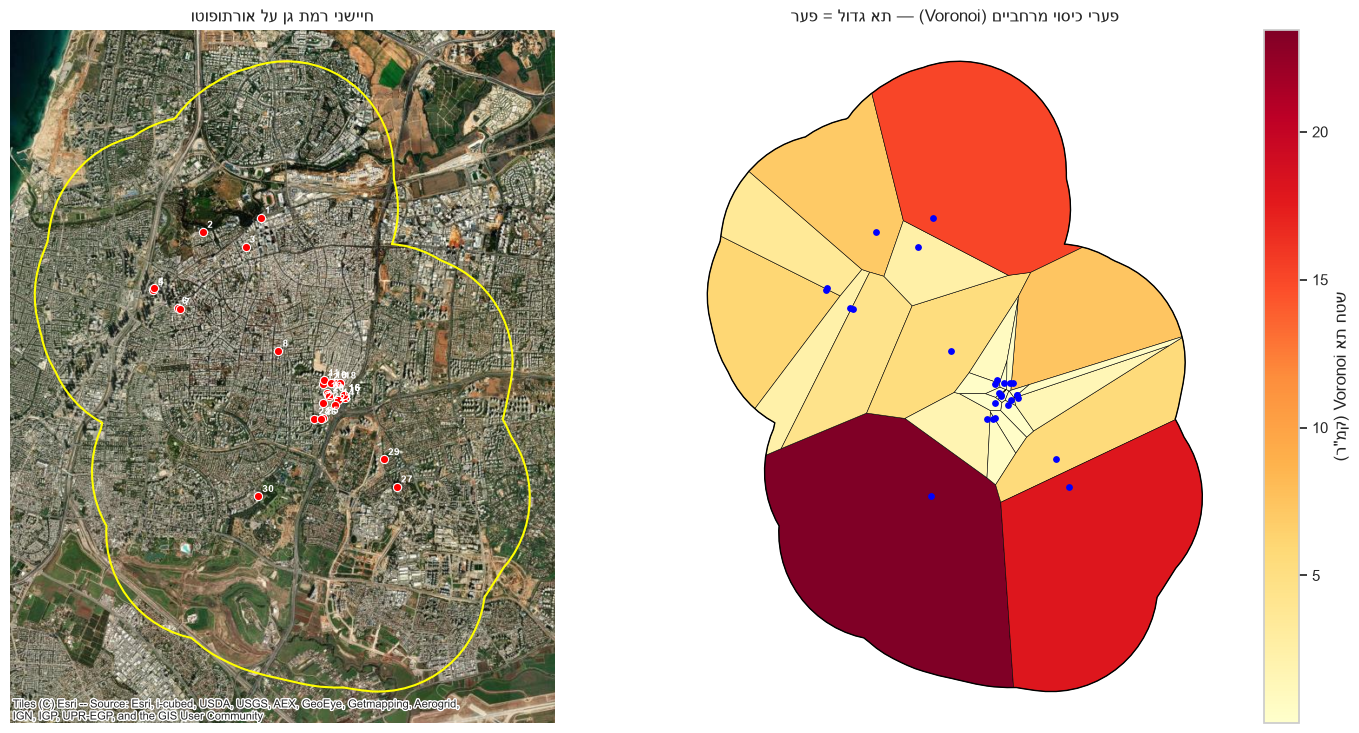

count    28.000000
mean      3.841829
std       5.913307
min       0.009968
25%       0.183688
50%       1.131051
75%       5.436462
max      23.450317
Name: area_km2, dtype: float64


In [4]:
boundary = gpd.read_file(BOUNDARY_PATH)
sensors_3857 = sensors_gdf.to_crs(3857)
boundary_3857 = boundary.to_crs(3857)
city_poly = boundary_3857.union_all()

outside = sensors_gdf[~sensors_gdf.within(boundary.union_all())]
print(f"{len(outside)} sensors fall outside the boundary polygon")

mp = MultiPoint(list(sensors_3857.geometry))
cells_gdf = gpd.GeoDataFrame(
    geometry=list(voronoi_polygons(mp, extend_to=city_poly).geoms), crs=3857
)
cells_gdf["geometry"] = cells_gdf.geometry.intersection(city_poly)
cells_gdf = cells_gdf[~cells_gdf.is_empty].copy()
cells_gdf["area_km2"] = cells_gdf.area / 1e6

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))

ax = axes[0]
boundary_3857.boundary.plot(ax=ax, color="yellow", linewidth=1.5)
sensors_3857.plot(ax=ax, color="red", markersize=35, edgecolor="white", linewidth=0.8, zorder=3)
for _, row in sensors_3857.iterrows():
    ax.annotate(str(row["serial"]), (row.geometry.x, row.geometry.y), fontsize=7, color="white",
                weight="bold", xytext=(3, 3), textcoords="offset points")
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldImagery, crs=sensors_3857.crs.to_string())
ax.set_title("חיישני רמת גן על אורתופוטו")
ax.set_axis_off()

ax2 = axes[1]
cells_gdf.plot(ax=ax2, column="area_km2", cmap="YlOrRd", edgecolor="black", linewidth=0.4,
               legend=True, legend_kwds={"label": 'שטח תא Voronoi (קמ"ר)'})
boundary_3857.boundary.plot(ax=ax2, color="black", linewidth=1)
sensors_3857.plot(ax=ax2, color="blue", markersize=15, zorder=3)
ax2.set_title("פערי כיסוי מרחביים (Voronoi) — תא גדול = פער")
ax2.set_axis_off()

plt.tight_layout()
plt.show()

print(cells_gdf["area_km2"].describe())


תאי ה-Voronoi הגדולים ביותר מסמנים את האזורים בעיר שהכי רחוקים מכל חיישן
קיים — אלה המועמדים הראשונים אם מתווספים חיישנים נוספים, ושווה להראות לאורן
במפורש איפה הם ביחס לשכונות/אזורי תעשייה שהוא מכיר.

**שימו לב:** `BOUNDARY_PATH` הוא לא גבול העיר האמיתי — ב-`scripts/fetch_geo.py`
(`BUFFER_M = 2000`) הוא נבנה מתוך גבול העירייה האמיתי (OSM) שמנופח החוצה
ב-2 ק"מ, כדי שהורדת הרסטרים (DEM/לווין) תכסה גם שוליים מחוץ לעיר. כלומר חלק
מהתאים ה"ריקים" שראינו למעלה הם בכלל מחוץ לעיר, לא פערי כיסוי אמיתיים.
בסעיף הבא נחשב הכל מול הגבול העירוני האמיתי.

## 3. כמה אחידה הפריסה בפועל — צפיפות ופערים מול הגבול העירוני האמיתי

In [5]:
import time

import numpy as np
import osmnx as ox
from geopy.geocoders import Nominatim
from scipy.spatial import cKDTree

admin = ox.geocode_to_gdf("Ramat Gan, Israel")
real_city_3857 = admin.to_crs(3857).union_all()

print(f"study-area boundary used for raster downloads (+2km buffer): {city_poly.area / 1e6:.1f} km2")
print(f"real municipal boundary (OSM): {real_city_3857.area / 1e6:.1f} km2")
print(f"density vs. buffered boundary: {len(sensors_3857) / (city_poly.area / 1e6):.2f} sensors/km2")
print(f"density vs. real municipal boundary: {len(sensors_3857) / (real_city_3857.area / 1e6):.2f} sensors/km2")


study-area boundary used for raster downloads (+2km buffer): 107.6 km2
real municipal boundary (OSM): 22.9 km2
density vs. buffered boundary: 0.26 sensors/km2
density vs. real municipal boundary: 1.22 sensors/km2


In [6]:
coords = np.array([[p.x, p.y] for p in sensors_3857.geometry])
tree = cKDTree(coords)
dist, idx = tree.query(coords, k=2)

nn_df = sensors_gdf[["serial"]].copy()
nn_df["nn_serial"] = sensors_gdf["serial"].values[idx[:, 1]]
nn_df["nn_dist_m"] = dist[:, 1]

print(nn_df["nn_dist_m"].describe())
print(f"pairs within 150m of their nearest neighbor: {(nn_df['nn_dist_m'] < 150).sum()} / {len(nn_df)}")
nn_df.sort_values("nn_dist_m").head(8)


count      28.000000
mean      307.791987
std       482.438035
min         1.488024
25%        48.315183
50%        82.035550
75%       327.289835
max      2106.344654
Name: nn_dist_m, dtype: float64
pairs within 150m of their nearest neighbor: 20 / 28


,serial,nn_serial,nn_dist_m
0,16,15,1.488024
12,15,16,1.488024
20,21,20,14.339563
19,20,21,14.339563
8,5,4,28.667654
9,4,5,28.667654
14,25,26,48.315183
24,26,25,48.315183


למעלה מ-20 מתוך 28 החיישנים נמצאים במרחק של פחות מ-150 מ' מהשכן הקרוב
ביותר שלהם — כלומר זה לא פיזור אחיד אלא אשכול (cluster) צפוף אחד, ומחוצה לו
פיזור הרבה יותר דליל. חיישנים 15 ו-16 במיוחד נמצאים 1.5 מטר זה מזה — בפועל
אותו עמוד.

In [7]:
real_cells = gpd.GeoDataFrame(
    geometry=list(voronoi_polygons(mp, extend_to=real_city_3857).geoms), crs=3857
)
real_cells["geometry"] = real_cells.geometry.intersection(real_city_3857)
real_cells = real_cells[~real_cells.is_empty].copy()
real_cells["area_km2"] = real_cells.area / 1e6
real_cells["cx"] = real_cells.centroid.x
real_cells["cy"] = real_cells.centroid.y
_, nearest_idx = tree.query(np.c_[real_cells["cx"], real_cells["cy"]])
real_cells["nearest_serial"] = sensors_gdf["serial"].values[nearest_idx]

print(real_cells["area_km2"].describe())
top_gaps = real_cells.sort_values("area_km2", ascending=False).head(5)
top_gaps_wgs = gpd.GeoDataFrame(
    top_gaps, geometry=gpd.points_from_xy(top_gaps["cx"], top_gaps["cy"]), crs=3857
).to_crs(4326)
top_gaps_wgs[["nearest_serial", "area_km2", "geometry"]]


count    28.000000
mean      0.819224
std       1.290751
min       0.009968
25%       0.105422
50%       0.306771
75%       0.848237
max       5.936562
Name: area_km2, dtype: float64


,nearest_serial,area_km2,geometry
1,30,5.936562,POINT (34.82471 32.04908)
27,27,3.243837,POINT (34.84411 32.04608)
6,8,2.596841,POINT (34.82299 32.07399)
11,24,1.822359,POINT (34.82762 32.06212)
14,29,1.505387,POINT (34.84274 32.05621)


In [8]:
geolocator = Nominatim(user_agent="urban-heat-mapping-research (academic, one-off lookup)")

def reverse(lat, lon):
    loc = geolocator.reverse((lat, lon), language="he", zoom=16)
    time.sleep(1.1)
    return loc.address if loc else None

cluster_lon, cluster_lat = 34.8365, 32.0675  # centroid of the tight serials-9-26-ish cluster
print("dense cluster neighborhood:", reverse(cluster_lat, cluster_lon))
for _, row in top_gaps_wgs.head(3).iterrows():
    print(f"gap near sensor {row['nearest_serial']} ({row['area_km2']:.1f} km2):",
          reverse(row.geometry.y, row.geometry.x))


dense cluster neighborhood: אצ"ל, רמת עמידר, רמת גן, נפת תל אביב, מחוז תל אביב, 5225517, ישראל


gap near sensor 30 (5.9 km2): אחד העם, רמת שקמה, רמת גן, נפת תל אביב, מחוז תל אביב, 5223403, ישראל


gap near sensor 27 (3.2 km2): תל השומר, רמת גן, נפת תל אביב, מחוז תל אביב, 5262657, ישראל


gap near sensor 8 (2.6 km2): עוזיאל, רמת יצחק, רמת גן, נפת תל אביב, מחוז תל אביב, 5238303, ישראל


**מה זה אומר בפועל:** מול הגבול העירוני האמיתי (לא המנופח), הצפיפות
הממוצעת נראית סבירה (~1.2 חיישנים/קמ"ר), אבל זה ממוצע מטעה — יותר מחצי
מהחיישנים דחוסים בטלאי אחד של כ-700 מ' (רמת עמידר/אזור הפארק), בעוד שאזורים
כמו תל השומר (קמפוס בי"ח/בסיס) ודרום העיר (רמת שקמה) כמעט ללא כיסוי, עם
פערים של עד כ-2 ק"מ לחיישן הקרוב ביותר.

זה בדיוק התבנית שגרמה לשיפור הרשת (notebook 06) להישבר ב-stress tests
(notebook 08) — לא חוסר בחיישנים בכלל, אלא חוסר בייצוג של כל סוג/אזור. אשכול
אחד דחוס ייתן המון איתות לשכונה אחת ואפס איתות לשאר העיר. שתי שאלות ישירות
לאורן: (1) זו פריסת פיילוט מכוונת שתורחב, או הפריסה הסופית? (2) חיישנים 15/16
— כפילות מכוונת או טעות?

## 4. קובץ המדידות (טמפרטורה) — היקף ואיכות

In [9]:
temp_df = pd.read_csv(TEMP_PATH)
temp_df = temp_df.rename(columns={"מספר סידורי": "serial", "temperature (°C)": "temp_c"})
temp_df["ts_utc"] = pd.to_datetime(temp_df["timestamp_local"], utc=True)

print(f"{len(temp_df):,} readings, {temp_df['serial'].nunique()} distinct sensors")
print("columns in the raw export:", temp_df.columns.tolist())
print("date range:", temp_df['ts_utc'].min(), "to", temp_df['ts_utc'].max())
print("raw UTC offsets seen in timestamp_local:", sorted(temp_df['timestamp_local'].str[-6:].unique()))


165,802 readings, 29 distinct sensors


columns in the raw export: ['timestamp_local', 'temp_c', 'serial', 'ts_utc']
date range: 2026-08-17 20:18:32+00:00 to 2026-11-15 20:17:32+00:00
raw UTC offsets seen in timestamp_local: ['+02:00', '+03:00']


שני offsetים (`+02:00`/`+03:00`) הם UTC+2/UTC+3 — שעון ישראל רגיל מול שעון
קיץ, לא תקלה. ל-join עם נתונים אחרים (ERA5 וכו') עדיף להמיר ל-UTC כמו שעשינו
כאן, ולא לסמוך על ה-offset המקומי.

In [10]:
per_sensor = (
    temp_df.sort_values("ts_utc")
    .groupby("serial")["ts_utc"]
    .agg(start="min", end="max", n_readings="count")
    .reset_index()
)
per_sensor["span_days"] = (per_sensor["end"] - per_sensor["start"]).dt.total_seconds() / 86400
per_sensor["median_interval_min"] = temp_df.sort_values("ts_utc").groupby("serial")["ts_utc"].apply(
    lambda s: s.diff().dt.total_seconds().median() / 60
).values
per_sensor["max_gap_hours"] = temp_df.sort_values("ts_utc").groupby("serial")["ts_utc"].apply(
    lambda s: s.diff().dt.total_seconds().max() / 3600
).values
per_sensor.sort_values("span_days")


,serial,start,end,n_readings,span_days,median_interval_min,max_gap_hours
11,12,2026-08-17 20:22:47+00:00,2026-09-02 15:39:47+00:00,764,15.803472,30.000000,25.820278
9,10,2026-08-17 20:19:22+00:00,2026-11-15 16:25:56+00:00,5296,89.837894,30.000000,6.243056
2,3,2026-08-17 20:23:52+00:00,2026-11-15 18:08:30+00:00,8480,89.905995,15.000000,8.340556
12,13,2026-08-17 20:29:31+00:00,2026-11-15 18:25:45+00:00,5326,89.914051,30.000000,2.110556
14,15,2026-08-17 20:27:12+00:00,2026-11-15 18:27:12+00:00,8513,89.916667,15.000000,6.352222
13,14,2026-08-17 20:21:47+00:00,2026-11-15 18:23:46+00:00,5281,89.918044,30.000000,8.182222
17,18,2026-08-17 20:22:08+00:00,2026-11-15 18:33:57+00:00,5322,89.924873,30.000000,4.096667
24,25,2026-08-17 20:29:27+00:00,2026-11-15 18:41:59+00:00,5342,89.925370,30.000000,2.104722
7,8,2026-08-17 20:23:01+00:00,2026-11-15 18:38:01+00:00,8506,89.927083,15.000000,4.328056
3,4,2026-08-17 20:27:38+00:00,2026-11-15 18:42:38+00:00,8506,89.927083,15.000000,6.343056


נקודות שבולטות מהטבלה:

- רוב החיישנים דגמו כל 30 דקות; חלק (1, 3, 4, 8, 15) דגמו כל 15 דקות — קצב
  לא אחיד בין חיישנים.
- חיישן 12 מפסיק לדווח אחרי כ-2.5 שבועות בלבד (עד 2026-09-02), בזמן שכל
  השאר רצים כל התקופה (~3 חודשים, עד 2026-11-15).
- יש פערים (gaps) של כמה שעות, ואצל חיישן 12 פער בודד של כ-26 שעות לפני
  שהפסיק לגמרי.

## 5. התאמה בין קובץ המיקומים לקובץ המדידות

In [11]:
gis_serials = set(sensors_gdf["serial"])
temp_serials = set(temp_df["serial"].unique())

print("serials with temperature but no GIS location:", sorted(temp_serials - gis_serials))
print("serials with a GIS location but no temperature data:", sorted(gis_serials - temp_serials))
print("missing serial numbers in the 1-30 range (never issued or decommissioned):",
      sorted(set(range(1, 31)) - gis_serials - temp_serials))


serials with temperature but no GIS location: [np.int64(13)]
serials with a GIS location but no temperature data: []
missing serial numbers in the 1-30 range (never issued or decommissioned): [28]


חיישן 13 מדווח טמפרטורות אבל לא מופיע בקובץ ה-GIS בכלל — אין לו מיקום ידוע.
מספר 28 חסר לגמרי משני הקבצים.

## 6. דבר נוסף שבולט: אין לחות בקובץ

שם הקובץ וה-`סוג חיישן` בקובץ ה-GIS הם "טמפרטורה ו**לחות**", אבל העמודה היחידה
במדידות היא טמפרטורה. ייתכן שזה export חלקי (temperature-only cut) ויש קובץ
לחות מקביל שלא נשלח אלינו.

## 7. התפלגות טמפרטורות + סדרת זמן לדוגמה

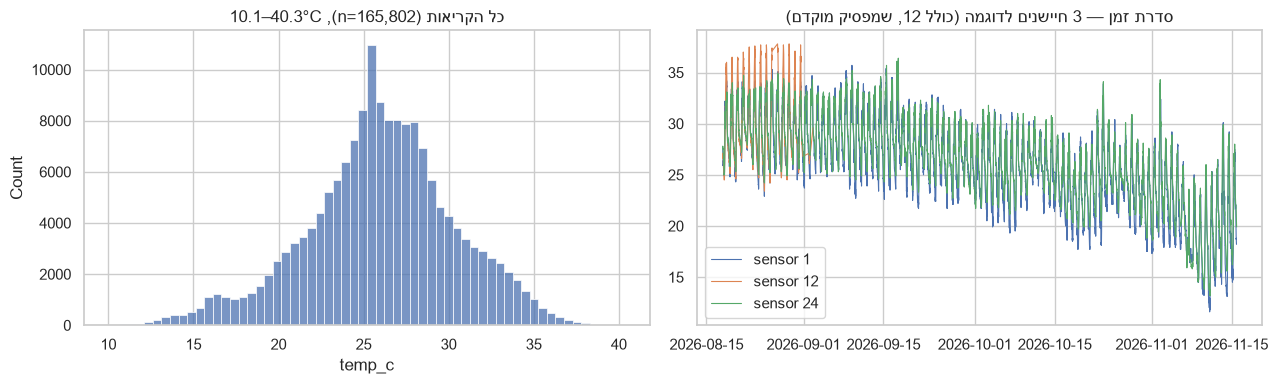

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(temp_df["temp_c"], bins=60, ax=axes[0])
axes[0].set_title(f"כל הקריאות (n={len(temp_df):,}), {temp_df['temp_c'].min():.1f}–{temp_df['temp_c'].max():.1f}°C")

sample_serials = [1, 12, 24]
for s in sample_serials:
    sub = temp_df[temp_df["serial"] == s].sort_values("ts_utc")
    axes[1].plot(sub["ts_utc"], sub["temp_c"], label=f"sensor {s}", linewidth=0.8)
axes[1].set_title("סדרת זמן — 3 חיישנים לדוגמה (כולל 12, שמפסיק מוקדם)")
axes[1].legend()
plt.tight_layout()
plt.show()


## 8. מול הפורמט של דורהאם — מה שונה

הדאטה המקורי של UrbanSENSE בדורהאם (`data/raw/Sensor_Data_Sensor_Info.csv`)
מגיע כבר עם טמפרטורה, לחות יחסית, Heat Index, Dew Point, וגם
Landcover_Type/Shade_Type/SVF/Percent_Vegetation מחוברים (joined) מראש לכל
שורה, בדגימה אחידה של 10 דקות.

הייצוא של רמת גן הוא raw export ישיר ממערכת WeTag: רק טמפרטורה, בלי שום
מטא-דאטה סביבתית, בקצב לא אחיד (15/30 דק') עם פערים. את ה-Landcover/Shade/SVF
יהיה צריך לגזור בעצמנו מה-pipeline הגיאוגרפי שכבר בנוי תחת
`data/raw/geo/ramat_gan/` (ותואם ל-`RAMAT_GAN` ב-`src/city_config.py`) —
לא לצפות שהם יגיעו מוכנים כמו בדורהאם.

## 9. שאלות פתוחות לקראת הפגישה עם אורן

- **לחות חסרה** — הקובץ נקרא "טמפרטורה ולחות" וה-GIS מגדיר את החיישנים ככאלה,
  אבל יש רק טמפרטורה ב-export. יש קובץ לחות מקביל שפשוט לא הגיע אלינו?
- **חיישן 13** — יש לו קריאות טמפרטורה לכל התקופה אבל אין לו שום רשומה בקובץ
  ה-GIS, כלומר אין לנו מיקום בשבילו. אפשר להשלים את זה?
- **חיישן 28 חסר לגמרי** — המספור קופץ מ-27 ל-29/30 בשני הקבצים. הוא הוסר/לא
  הותקן מעולם, או שזו רק דילוג במספור הסידורי?
- **חיישן 12 הפסיק לדווח אחרי ~2.5 שבועות** (2026-09-02, מול ~3 חודשים
  לכולם). תקלה ידועה? יש סיכוי שימשיך לדווח, או שכדאי להתייחס אליו כ"מת"
  ולהוציא אותו מהניתוח?
- **קצב דגימה לא אחיד** — חלק מהחיישנים כל 15 דק', חלק כל 30, עם פערים של
  כמה שעות (ועד 26 שעות אצל 12). זה מאפיין ידוע של ה-feed/קישוריות, או שיש
  מקור נתונים נקי יותר (API ישיר של WeTag) שכדאי לנו למשוך ממנו במקום את
  ה-export הזה?
- **גובה/כיוון התקנה** — כל החיישנים מותקנים על עמודי תאורה/חשמל. יש מידע
  על גובה ההתקנה או הגנת קרינה (radiation shield) על החיישן עצמו? זה משפיע
  על ההשוואתיות מול הנתונים המוצללים/לא-מוצללים של דורהאם.
- **טווח התאריכים** — ה-export מכסה 2026-08-17 עד 2026-11-15 (~3 חודשים).
  זו כל ההיסטוריה שיש, או שהפריסה ממשיכה ונקבל עדכונים נוספים? משנה
  משמעותית לניתוח עקומת מספר-החיישנים (notebook 09).
- **הערות השטח** (למשל "ליד ברזיה ומתקני ילדים, חם") — יש גרסה מורחבת יותר
  של המטא-דאטה הזה, או שזה כל מה שתועד בשטח?
- **הפריסה מרוכזת בפועל** — יותר מחצי מהחיישנים יושבים בטלאי אחד של ~700 מ'
  סביב רמת עמידר/הפארק, בזמן שאזורים כמו תל השומר ודרום העיר (רמת שקמה)
  כמעט לא מכוסים. זו פריסת פיילוט מכוונת (ויתווספו עוד חיישנים באזורים
  האחרים), או זו הפריסה הסופית המתוכננת?
- **חיישנים 15 ו-16** יושבים במרחק 1.5 מטר זה מזה — בעצם אותו עמוד. זו
  כפילות מכוונת (redundancy/כיול), טעות הזנה, או שאחד מהם בעצם מחליף את
  השני (עמוד שהוחלף)?
